# Ji et al. 2020 — Cutaneous SCC
## 03 · Embryonic-module signatures along the trajectory

The three embryonic modules on the linear manifold and against pseudotime. Because the geometry is **non-branching**, the read is a *gradient* test (not a bifurcation): Gastrulation and Somitogenesis **overlap** at the Gast/pSom-high origin and co-decline, while Neural-Crest is the **inverse terminal gradient** — the §1 non-branching signature. Signatures are graph-smoothed (10x noise floor); the smoothed-vs-raw choice is the binding Chen lesson.

In [1]:
import os, sys, glob, warnings; warnings.filterwarnings('ignore')
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd, scanpy as sc, scFates as scf
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
sc.settings.verbosity = 1; SEED = 1

In [2]:
name = os.path.basename(os.getcwd()); cat = os.path.basename(os.path.dirname(os.getcwd()))
pth = os.path.join(*([os.pardir]*4)); pth_data = os.path.join(pth,'data')
pth_out = os.path.join(pth_data,'cancer', 'vertebrate', 'CCCA', 'claude',cat,name)
pth_fig = os.path.join(pth,'figures', 'mesencontext', 'claude',cat,name)
pth_cb  = os.path.join(pth_fig,'colorbars'); os.makedirs(pth_cb, exist_ok=True)
print('dataset:', name)

dataset: Ji2020_Skin-3


In [3]:
adata = sc.read_h5ad(os.path.join(pth_out, 'manifold.h5ad'))
modules = {'Gast_sm':'Gastrulation Signature', 'pSom_sm':'Somitogenesis Signature', 'Crest_sm':'Neural Crest Signature'}
print(adata.shape, '| pseudotime', round(adata.obs.t.min(),2), '->', round(adata.obs.t.max(),2))

(6897, 21042) | pseudotime 0.0 -> 8.31


### Module maps on the linear manifold (house layout)

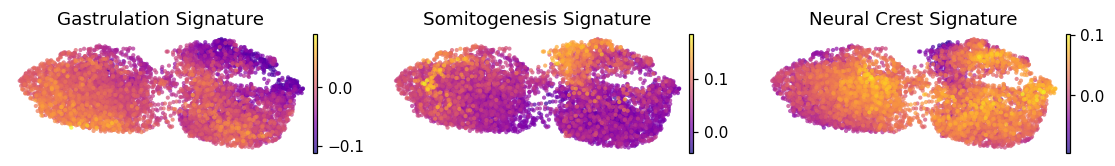

In [4]:
plot = adata.copy(); plot.obsm['X_umap'] = plot.obsm['X_umap_lin']
xl = plot.obsm['X_umap']
xlo,xhi = np.percentile(xl[:,0],[0.3,99.7]); ylo,yhi = np.percentile(xl[:,1],[0.3,99.7])
px=(xhi-xlo)*.05; py=(yhi-ylo)*.08
fig, axes = plt.subplots(1, 3, figsize=(10.5,1.6))
for ax,(m,title) in zip(axes, modules.items()):
    sc.pl.umap(plot, color=m, cmap='plasma', alpha=.7, size=30, colorbar_loc='right',
               frameon=False, show=False, ax=ax, title=title)
    ax.set_xlim(xlo-px,xhi+px); ax.set_ylim(ylo-py,yhi+py)
fig.tight_layout(); plt.show()

### Signatures vs pseudotime — gradient, not bifurcation
Gast and pSom decline together from the origin; Crest rises to the terminus. Spearman rho quantifies each monotone trend (the non-branching gradient).

{'Gast_sm': np.float64(-0.499), 'pSom_sm': np.float64(-0.388), 'Crest_sm': np.float64(0.31)}


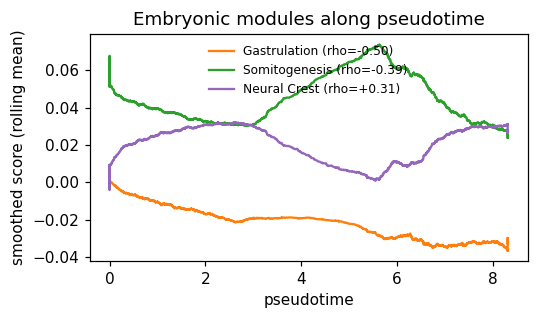

In [5]:
t = adata.obs['t'].values
fig, ax = plt.subplots(figsize=(5,3))
for m,c,lab in [('Gast_sm','tab:orange','Gastrulation'),('pSom_sm','tab:green','Somitogenesis'),('Crest_sm','tab:purple','Neural Crest')]:
    o = np.argsort(t); yv = pd.Series(adata.obs[m].values[o]).rolling(400,min_periods=1,center=True).mean()
    ax.plot(t[o], yv, color=c, label='%s (rho=%+.2f)' % (lab, spearmanr(t, adata.obs[m])[0]))
ax.set_xlabel('pseudotime'); ax.set_ylabel('smoothed score (rolling mean)'); ax.legend(fontsize=8, frameon=False)
ax.set_title('Embryonic modules along pseudotime'); fig.tight_layout(); plt.show()
print({m: round(spearmanr(t, adata.obs[m])[0],3) for m in modules})

### Save `signatures.h5ad`

In [6]:
adata.write(os.path.join(pth_out, 'signatures.h5ad')); print('saved signatures.h5ad')

saved signatures.h5ad


### `{Gast,pSom,Crest}_signature.pdf` + external colorbars (house style)

saved 3 signature PDFs + colorbars


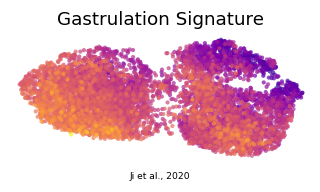

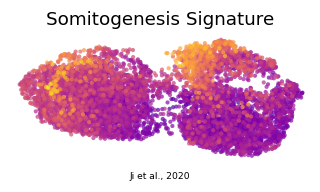

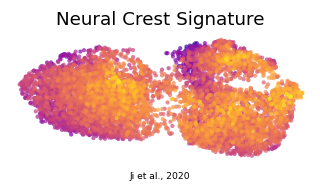

In [7]:
plot = adata.copy(); plot.obsm['X_umap'] = plot.obsm['X_umap_lin']
xl = plot.obsm['X_umap']
xlo,xhi = np.percentile(xl[:,0],[0.3,99.7]); ylo,yhi = np.percentile(xl[:,1],[0.3,99.7])
px=(xhi-xlo)*.05; py=(yhi-ylo)*.08
titles = {'Gast':'Gastrulation Signature','pSom':'Somitogenesis Signature','Crest':'Neural Crest Signature'}
for m,lab in [('Gast_sm','Gast'),('pSom_sm','pSom'),('Crest_sm','Crest')]:
    fig, ax = plt.subplots(figsize=(3.5,1.5))
    sc.pl.umap(plot, color=m, cmap='plasma', alpha=.7, size=30, colorbar_loc=None,
               frameon=False, show=False, ax=ax, title=titles[lab])
    ax.set_xlim(xlo-px,xhi+px); ax.set_ylim(ylo-py,yhi+py)
    ax.text(.5,-.14,'Ji et al., 2020', ha='center', transform=ax.transAxes, size=6)
    fig.savefig(os.path.join(pth_fig, f'{lab}_signature.pdf'), bbox_inches='tight')
    lo,hi = float(adata.obs[m].min()), float(adata.obs[m].max())
    fcb = plt.figure(figsize=(.66,1)); cax = fcb.add_axes([.35,.05,.3,.9])
    cb = plt.colorbar(ax.collections[0], cax=cax); cb.set_ticks(np.round(np.linspace(lo,hi,5),2))
    cb.ax.tick_params(size=0, labelsize=6)
    fcb.savefig(os.path.join(pth_cb, f'{lab}_signature.pdf'), bbox_inches='tight'); plt.close(fcb)
    plt.show()
print('saved 3 signature PDFs + colorbars')